In [22]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from xgboost import XGBClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,classification_report, confusion_matrix, ConfusionMatrixDisplay)

In [23]:
df = pd.read_csv("Banglore_traffic_Dataset.csv")
df

,Date,Area Name,Road/Intersection Name,Traffic Volume,Average Speed,Travel Time Index,Congestion Level,Road Capacity Utilization,Incident Reports,Environmental Impact,Public Transport Usage,Traffic Signal Compliance,Parking Usage,Pedestrian and Cyclist Count,Weather Conditions,Roadwork and Construction Activity
0,2022-01-01,Indiranagar,100 Feet Road,50590,50.230299,1.500000,100.000000,100.000000,0,151.180,70.632330,84.044600,85.403629,111,Clear,No
1,2022-01-01,Indiranagar,CMH Road,30825,29.377125,1.500000,100.000000,100.000000,1,111.650,41.924899,91.407038,59.983689,100,Clear,No
2,2022-01-01,Whitefield,Marathahalli Bridge,7399,54.474398,1.039069,28.347994,36.396525,0,64.798,44.662384,61.375541,95.466020,189,Clear,No
3,2022-01-01,Koramangala,Sony World Junction,60874,43.817610,1.500000,100.000000,100.000000,1,171.748,32.773123,75.547092,63.567452,111,Clear,No
4,2022-01-01,Koramangala,Sarjapur Road,57292,41.116763,1.500000,100.000000,100.000000,3,164.584,35.092601,64.634762,93.155171,104,Clear,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8931,2024-08-09,Electronic City,Hosur Road,11387,23.440276,1.262384,35.871483,57.354487,1,72.774,21.523289,83.530352,97.898279,211,Fog,No
8932,2024-08-09,M.G. Road,Trinity Circle,36477,45.168429,1.500000,100.000000,100.000000,3,122.954,29.822312,60.738488,60.355967,95,Clear,No
8933,2024-08-09,M.G. Road,Anil Kumble Circle,42822,22.028609,1.500000,100.000000,100.000000,1,135.644,43.185905,85.321627,61.333731,110,Clear,No
8934,2024-08-09,Jayanagar,South End Circle,20540,52.254798,1.020520,72.639152,97.845527,2,91.080,44.416043,89.586947,79.197198,94,Clear,No


In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8936 entries, 0 to 8935
Data columns (total 16 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Date                                8936 non-null   str    
 1   Area Name                           8936 non-null   str    
 2   Road/Intersection Name              8936 non-null   str    
 3   Traffic Volume                      8936 non-null   int64  
 4   Average Speed                       8936 non-null   float64
 5   Travel Time Index                   8936 non-null   float64
 6   Congestion Level                    8936 non-null   float64
 7   Road Capacity Utilization           8936 non-null   float64
 8   Incident Reports                    8936 non-null   int64  
 9   Environmental Impact                8936 non-null   float64
 10  Public Transport Usage              8936 non-null   float64
 11  Traffic Signal Compliance           8936 non-null   fl

In [25]:
df.shape

(8936, 16)

In [26]:
df.isnull().sum()

Date                                  0
Area Name                             0
Road/Intersection Name                0
Traffic Volume                        0
Average Speed                         0
Travel Time Index                     0
Congestion Level                      0
Road Capacity Utilization             0
Incident Reports                      0
Environmental Impact                  0
Public Transport Usage                0
Traffic Signal Compliance             0
Parking Usage                         0
Pedestrian and Cyclist Count          0
Weather Conditions                    0
Roadwork and Construction Activity    0
dtype: int64

In [27]:
df.duplicated().sum()

np.int64(0)

In [28]:
 df.describe()

,Traffic Volume,Average Speed,Travel Time Index,Congestion Level,Road Capacity Utilization,Incident Reports,Environmental Impact,Public Transport Usage,Traffic Signal Compliance,Parking Usage,Pedestrian and Cyclist Count
count,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000
mean,29236.048120,39.447427,1.375554,80.818041,92.029215,1.570389,108.472096,45.086651,79.950243,75.155597,114.533348
std,13001.808801,10.707244,0.165319,23.533182,16.583341,1.420047,26.003618,20.208460,11.585006,14.409394,36.812573
min,4233.000000,20.000000,1.000039,5.160279,18.739771,0.000000,58.466000,10.006853,60.003933,50.020411,66.000000
25%,19413.000000,31.775825,1.242459,64.292905,97.354990,0.000000,88.826000,27.341191,69.828270,62.545895,94.000000
50%,27600.000000,39.199368,1.500000,92.389018,100.000000,1.000000,105.200000,45.170684,79.992773,75.317610,102.000000
75%,38058.500000,46.644517,1.500000,100.000000,100.000000,2.000000,126.117000,62.426485,89.957358,87.518589,111.000000
max,72039.000000,89.790843,1.500000,100.000000,100.000000,10.000000,194.078000,79.979744,99.993652,99.995049,243.000000


In [29]:
df.dtypes

Date                                      str
Area Name                                 str
Road/Intersection Name                    str
Traffic Volume                          int64
Average Speed                         float64
Travel Time Index                     float64
Congestion Level                      float64
Road Capacity Utilization             float64
Incident Reports                        int64
Environmental Impact                  float64
Public Transport Usage                float64
Traffic Signal Compliance             float64
Parking Usage                         float64
Pedestrian and Cyclist Count            int64
Weather Conditions                        str
Roadwork and Construction Activity        str
dtype: object

In [30]:
#convert categories

df["Congestion_Category"] = pd.cut(
    df["Congestion Level"],
    bins=[-0.001, 35, 70, 100.001],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

In [31]:
df["Congestion_Category"].value_counts()

Congestion_Category
High      6339
Medium    2075
Low        522
Name: count, dtype: int64

In [32]:
X = df.drop(columns=["Congestion Level", "Congestion_Category", "Date"])
y = df["Congestion_Category"]

In [33]:
#Identified numerical and categorical columns.

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "str"]).columns.tolist()
print("Numerical:", numeric_features)
print("Categorical:", categorical_features)

Numerical: ['Traffic Volume', 'Average Speed', 'Travel Time Index', 'Road Capacity Utilization', 'Incident Reports', 'Environmental Impact', 'Public Transport Usage', 'Traffic Signal Compliance', 'Parking Usage', 'Pedestrian and Cyclist Count']
Categorical: ['Area Name', 'Road/Intersection Name', 'Weather Conditions', 'Roadwork and Construction Activity']


In [34]:
for col in numeric_features:
    X[col] = X[col].fillna(X[col].mean())

In [35]:
for col in categorical_features:
    X[col] = X[col].fillna(X[col].mode()[0])

In [36]:
df.dtypes

Date                                       str
Area Name                                  str
Road/Intersection Name                     str
Traffic Volume                           int64
Average Speed                          float64
Travel Time Index                      float64
Congestion Level                       float64
Road Capacity Utilization              float64
Incident Reports                         int64
Environmental Impact                   float64
Public Transport Usage                 float64
Traffic Signal Compliance              float64
Parking Usage                          float64
Pedestrian and Cyclist Count             int64
Weather Conditions                         str
Roadwork and Construction Activity         str
Congestion_Category                   category
dtype: object

In [37]:
X_encoded = X.copy()
label_encoders = {}
for col in categorical_features:
    le = LabelEncoder()
    X_encoded[col] = le.fit_transform(X_encoded[col].astype(str))
    label_encoders[col] = le

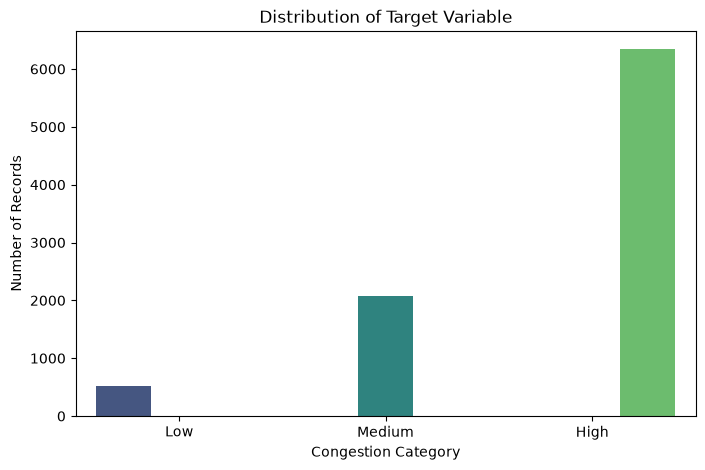

In [ ]:

sns.countplot(
    data=df,
    x="Congestion_Category",
    order=["Low", "Medium", "High"],
    hue="Congestion_Category",
    palette="viridis",
    legend=False
)
plt.title("Distribution of Target Variable")
plt.xlabel("Congestion Category")
plt.ylabel("Number of Records")
plt.show()

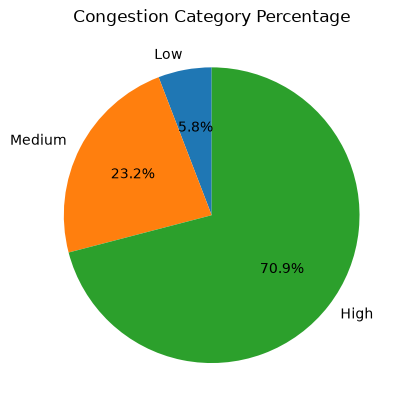

In [48]:
#Target variable pie chart
df["Congestion_Category"].value_counts().reindex(
    ["Low", "Medium", "High"]
).plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Congestion Category Percentage")
plt.ylabel("")
plt.show()

sns.countplot(
    data=df,
    x="Weather Conditions",
    hue="Congestion_Category",
    hue_order=["Low", "Medium", "High"]
)

plt.title("Congestion Category by Weather Conditions")
plt.xlabel("Weather Conditions")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [40]:
X_train, X_test, y_train, y_test = train_test_split(X_encoded,y,test_size=0.2,random_state=42,stratify=y)
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (7148, 14)
Testing Data: (1788, 14)


In [41]:
# scaling Logistic Regression model
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [42]:
#Logistic Regression model

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)
lr_accuracy = accuracy_score(y_test, lr_pred)
print("Logistic Regression Accuracy:", lr_accuracy)

Logistic Regression Accuracy: 0.9440715883668904


In [43]:
#Random Forest

rf_model = RandomForestClassifier(n_estimators=200,random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)
print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.941834451901566


In [44]:
#GradientBoosting

gb_model = GradientBoostingClassifier(n_estimators=100,random_state=42)
gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)
gb_accuracy = accuracy_score(y_test, gb_pred)
print("Gradient Boosting Accuracy:", gb_accuracy)

Gradient Boosting Accuracy: 0.9395973154362416


In [45]:
# XGBoost

target_encoder = LabelEncoder()
y_train_encoded = target_encoder.fit_transform(y_train)
y_test_encoded = target_encoder.transform(y_test)
xgb_model = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42, eval_metric="mlogloss")
xgb_model.fit(X_train, y_train_encoded)
xgb_pred = xgb_model.predict(X_test)
xgb_accuracy = accuracy_score(y_test_encoded, xgb_pred)
print("XGBoost Accuracy:", xgb_accuracy)

XGBoost Accuracy: 0.9440715883668904


In [ ]:
#all models

comparison = pd.DataFrame({
    "Model": ["Logistic Regression","Random Forest", "Gradient Boosting","XGBoost"],
    "Accuracy": [lr_accuracy,rf_accuracy,gb_accuracy,xgb_accuracy]})
print(comparison)

                 Model  Accuracy
0  Logistic Regression  0.944072
1        Random Forest  0.941834
2    Gradient Boosting  0.939597
3              XGBoost  0.944072


In [ ]:
models = {"Logistic Regression": (lr_model, lr_pred),"Random Forest": (rf_model, rf_pred),"Gradient Boosting": (gb_model, gb_pred),"XGBoost": (xgb_model, xgb_pred)}
best_model_name = comparison.loc[comparison["Accuracy"].idxmax(), "Model"]
best_model = models[best_model_name][0]
best_pred = models[best_model_name][1]
print("Best Model:", best_model_name)
print("Best Accuracy:",accuracy_score(y_test, best_pred))

Best Model: Logistic Regression
Best Accuracy: 0.9440715883668904


In [52]:
models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model,
    "XGBoost": xgb_model
}

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost"
    ],
    "Accuracy": [
        lr_accuracy,
        rf_accuracy,
        gb_accuracy,
        xgb_accuracy
    ]
})

best_model_name = comparison.loc[
    comparison["Accuracy"].idxmax(), "Model"
]

best_model = models[best_model_name]

print("Best Model:", best_model_name)
print("Best Accuracy:", comparison["Accuracy"].max())

Best Model: Logistic Regression
Best Accuracy: 0.9440715883668904


In [54]:
import os
import joblib

os.makedirs("models", exist_ok=True)
artifact = {"model": best_model,"model_name": best_model_name, "target_encoder": (
        target_encoder if best_model_name == "XGBoost" else None),
    "feature_columns": X_encoded.columns.tolist(),"classes": ["Low", "Medium", "High"]}
joblib.dump( artifact, "models/best_traffic_model.pkl")
print("Best model saved successfully!")

Best model saved successfully!


In [55]:
loaded_artifact = joblib.load(
    "models/best_traffic_model.pkl"
)

print("Model:", loaded_artifact["model_name"])
print("Classes:", loaded_artifact["classes"])
print("Saved successfully!")

Model: Logistic Regression
Classes: ['Low', 'Medium', 'High']
Saved successfully!


In [60]:
import os
import joblib
import numpy as np

# 1. Select the best model
models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model,
    "XGBoost": xgb_model
}

best_model_name = comparison.iloc[0]["Model"]
best_model = models[best_model_name]
best_accuracy = float(comparison.iloc[0]["Accuracy"])

# 2. Identify columns
numeric_columns = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = list(label_encoders.keys())

# 3. Create fill values
numeric_fill_values = {
    col: X[col].mean() for col in numeric_columns
}

categorical_fill_values = {
    col: X[col].mode()[0] for col in categorical_columns
}

# 4. Create complete artifact
artifact = {
    "model": best_model,
    "model_name": best_model_name,
    "accuracy": best_accuracy,
    "feature_columns": X_encoded.columns.tolist(),
    "numeric_columns": numeric_columns,
    "categorical_columns": categorical_columns,
    "numeric_fill_values": numeric_fill_values,
    "categorical_fill_values": categorical_fill_values,
    "label_encoders": label_encoders,
    "scaler": scaler if best_model_name == "Logistic Regression" else None,
    "target_encoder": target_encoder if best_model_name == "XGBoost" else None,
    "classes": ["Low", "Medium", "High"]
}

# 5. Save to models folder
os.makedirs("models", exist_ok=True)

model_path = os.path.abspath(
    "models/best_traffic_model.pkl"
)

joblib.dump(artifact, model_path)

print("MODEL SAVED SUCCESSFULLY!")
print("Best model:", best_model_name)
print("Accuracy:", round(best_accuracy * 100, 2), "%")

MODEL SAVED SUCCESSFULLY!
Best model: Logistic Regression
Accuracy: 94.41 %


In [61]:
loaded_artifact = joblib.load(model_path)

print("Model:", loaded_artifact["model_name"])
print("Accuracy:", loaded_artifact["accuracy"])
print("\nAvailable keys:")

print(list(loaded_artifact.keys()))

Model: Logistic Regression
Accuracy: 0.9440715883668904

Available keys:
['model', 'model_name', 'accuracy', 'feature_columns', 'numeric_columns', 'categorical_columns', 'numeric_fill_values', 'categorical_fill_values', 'label_encoders', 'scaler', 'target_encoder', 'classes']
